In [84]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [85]:
df = pd.read_csv("data.csv")
df.head()
df.info()
df.describe()
df.shape
df.columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   OrderID          1200 non-null   object 
 1   Date             1200 non-null   object 
 2   CustomerID       1200 non-null   object 
 3   Product          1200 non-null   object 
 4   Quantity         1200 non-null   int64  
 5   UnitPrice        1200 non-null   float64
 6   ShippingAddress  1200 non-null   object 
 7   PaymentMethod    1200 non-null   object 
 8   OrderStatus      1200 non-null   object 
 9   TrackingNumber   1200 non-null   object 
 10  ItemsInCart      1200 non-null   int64  
 11  CouponCode       891 non-null    object 
 12  ReferralSource   1200 non-null   object 
 13  TotalPrice       1200 non-null   float64
dtypes: float64(2), int64(2), object(10)
memory usage: 131.4+ KB


Index(['OrderID', 'Date', 'CustomerID', 'Product', 'Quantity', 'UnitPrice',
       'ShippingAddress', 'PaymentMethod', 'OrderStatus', 'TrackingNumber',
       'ItemsInCart', 'CouponCode', 'ReferralSource', 'TotalPrice'],
      dtype='object')

In [106]:
df.isnull().sum()
duplicates = df.duplicated().sum()
print("Duplicate rows:", duplicates)

if duplicates > 0:
    df = df.drop_duplicates()

Duplicate rows: 0


In [87]:
df["Product"].value_counts()
df["PaymentMethod"].value_counts()
df["OrderStatus"].value_counts()

OrderStatus
Cancelled    250
Returned     247
Pending      237
Shipped      235
Delivered    231
Name: count, dtype: int64

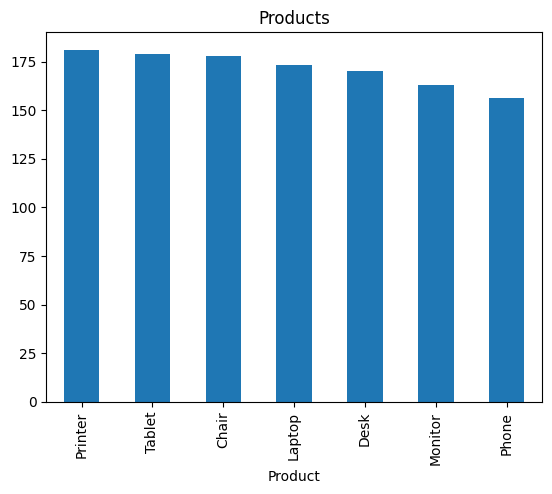

In [88]:
df["Product"].value_counts().plot(kind="bar")

plt.title("Products")
plt.show()


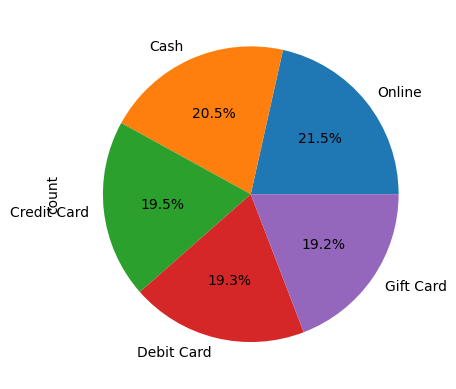

In [89]:
df["PaymentMethod"].value_counts().plot(kind="pie", autopct="%1.1f%%")

plt.show()

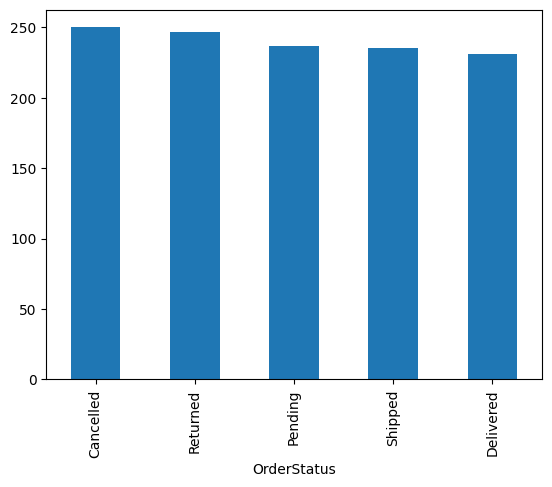

In [90]:
df["OrderStatus"].value_counts().plot(kind="bar")

plt.show()

In [91]:
df["Product"].value_counts().idxmax()


'Printer'

In [92]:
df["TotalPrice"].mean()

np.float64(1053.9683)

In [93]:
df["TotalPrice"].max()

np.float64(3456.4)

In [94]:
df["TotalPrice"].min()

np.float64(11.39)

In [95]:
df["Quantity"].mean()

np.float64(2.9458333333333333)

In [96]:
df[df["TotalPrice"] > 2000]

,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice
0,ORD200000,2023-01-04,C72649,Monitor,5,570.62,928 Main St,Debit Card,Shipped,TRK37947903,7,SAVE10,Instagram,2853.10
2,ORD200002,2024-02-27,C81728,Tablet,5,550.68,512 Main St,Credit Card,Cancelled,TRK42903982,8,FREESHIP,Email,2753.40
4,ORD200004,2025-05-08,C81840,Printer,4,626.01,668 Main St,Online,Delivered,TRK29241424,8,SAVE10,Email,2504.04
9,ORD200009,2023-11-21,C31946,Desk,4,509.38,102 Main St,Credit Card,Shipped,TRK33478363,6,SAVE10,Google,2037.52
10,ORD200010,2023-12-29,C43443,Tablet,5,625.97,333 Main St,Credit Card,Returned,TRK98859248,9,WINTER15,Instagram,3129.85
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1155,ORD201155,2023-08-13,C41478,Printer,4,534.57,667 Main St,Credit Card,Delivered,TRK62068126,6,FREESHIP,Facebook,2138.28
1156,ORD201156,2023-07-19,C20512,Laptop,4,690.78,980 Main St,Credit Card,Shipped,TRK98234737,9,NaN,Referral,2763.12
1171,ORD201171,2023-08-28,C39911,Phone,4,518.40,699 Main St,Credit Card,Delivered,TRK80431998,7,SAVE10,Facebook,2073.60
1179,ORD201179,2023-01-08,C84630,Laptop,5,518.55,907 Main St,Credit Card,Cancelled,TRK48054997,6,WINTER15,Instagram,2592.75


In [107]:
df["CouponCode"] = df["CouponCode"].fillna("No Coupon")

In [98]:
Q1 = df["TotalPrice"].quantile(0.25)
Q3 = df["TotalPrice"].quantile(0.75)

IQR = Q3 - Q1

In [99]:
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

In [108]:
outliers = df[
    (df["TotalPrice"] < lower) |
    (df["TotalPrice"] > upper)
]

outliers

df = df[
    (df["TotalPrice"] >= lower) &
    (df["TotalPrice"] <= upper)
]

In [101]:
df["PricePerItem"] = df["TotalPrice"] / df["Quantity"]

In [102]:
df["UsedCoupon"] = df["CouponCode"] != "No Coupon"

In [103]:
df["LargeOrder"] = df["Quantity"] >= 4

In [104]:
df.head()

,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice,PricePerItem,UsedCoupon,LargeOrder
0,ORD200000,2023-01-04,C72649,Monitor,5,570.62,928 Main St,Debit Card,Shipped,TRK37947903,7,SAVE10,Instagram,2853.10,570.62,True,True
1,ORD200001,2024-08-23,C75739,Phone,2,151.35,823 Main St,Online,Shipped,TRK91186779,3,SAVE10,Referral,302.70,151.35,True,False
2,ORD200002,2024-02-27,C81728,Tablet,5,550.68,512 Main St,Credit Card,Cancelled,TRK42903982,8,FREESHIP,Email,2753.40,550.68,True,True
3,ORD200003,2023-10-15,C33540,Chair,1,273.19,275 Main St,Debit Card,Returned,TRK62788070,5,SAVE10,Facebook,273.19,273.19,True,False
4,ORD200004,2025-05-08,C81840,Printer,4,626.01,668 Main St,Online,Delivered,TRK29241424,8,SAVE10,Email,2504.04,626.01,True,True


In [109]:
df.to_csv("cleaned_data.csv", index=False)

In [ ]:
'''
Project Summary
Dataset loaded successfully.
Explored the dataset using Pandas.
Checked and handled missing values.
Checked duplicate records.
Detected and handled outliers using IQR.
Created three new features:
PricePerItem
UsedCoupon
LargeOrder
Saved the cleaned dataset as cleaned_data.csv.
'''